# Chunking PDF and Podcast Sources

In [1]:
from pathlib import Path
import os, json, re, hashlib, subprocess, importlib.metadata, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dotenv import load_dotenv
from pypdf import PdfReader
from openai import OpenAI
import tiktoken
from langchain_text_splitters import CharacterTextSplitter, RecursiveCharacterTextSplitter, TokenTextSplitter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
ROOT = Path.cwd()
DATA, RESULTS = ROOT / 'data', ROOT / 'results'
DATA.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
load_dotenv(ROOT / '.env')
logging.getLogger('langchain_text_splitters.base').setLevel(logging.ERROR)
enc = tiktoken.get_encoding('cl100k_base')
def nt(text): return len(enc.encode(text, disallowed_special=()))
packages = ['langchain-text-splitters','pypdf','openai','tiktoken','pandas','matplotlib','python-dotenv','nbformat','nbclient','ipykernel','scikit-learn']
# Version reporting must not require optional notebook-authoring tools.
versions = {}
missing_metadata = []
for name in packages:
    try:
        versions[name] = importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        missing_metadata.append(name)
if missing_metadata:
    print("Version metadata unavailable (skipped):", ", ".join(missing_metadata))
(RESULTS / 'environment.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
print('Required imports succeeded. API key configured:', bool(os.getenv('OPENAI_API_KEY')))

Version metadata unavailable (skipped): nbformat, nbclient
Required imports succeeded. API key configured: True


## 1. Load the two assigned sources

In [2]:
SOURCE = ROOT.parent
AUDIO = SOURCE / 'The_Blueprint_For_Trustworthy_AI.m4a'
PDF = next(SOURCE.glob('ai_hleg_ethics_guidelines*.pdf'))
manifest = {p.name: {'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in [AUDIO,PDF]}
(DATA / 'source_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
transcript_path = DATA / 'transcript.json'
if not transcript_path.exists():
    pieces = DATA / '_pieces'; pieces.mkdir(exist_ok=True)
    subprocess.run(['ffmpeg','-v','error','-y','-i',str(AUDIO),'-ac','1','-b:a','64k','-f','segment','-segment_time','600','-reset_timestamps','1',str(pieces/'piece_%02d.mp3')],check=True)
    client = OpenAI(timeout=180, max_retries=2)
    segments = []
    for i,piece in enumerate(sorted(pieces.glob('piece_*.mp3'))):
        cache = piece.with_suffix('.json')
        if cache.exists(): result = json.loads(cache.read_text(encoding='utf-8'))
        else:
            with piece.open('rb') as stream:
                response = client.audio.transcriptions.create(model='whisper-1',file=stream,response_format='verbose_json',timestamp_granularities=['segment'])
            result = response.model_dump()
            cache.write_text(json.dumps(result,indent=2),encoding='utf-8')
        for seg in result['segments']:
            segments.append({'start':seg['start']+600*i,'end':seg['end']+600*i,'text':seg['text'].strip()})
        print('Transcribed piece',i+1,flush=True)
    transcript_path.write_text(json.dumps(segments,indent=2),encoding='utf-8')
segments = json.loads(transcript_path.read_text(encoding='utf-8'))
# Preserve the natural continuous transcript rather than inventing speaker turns.
podcast_text = ' '.join(s['text'] for s in segments)
cursor = 0
for seg in segments:
    seg['char_start'] = cursor; seg['char_end'] = cursor+len(seg['text']); cursor=seg['char_end']+1
transcript_path.write_text(json.dumps(segments,indent=2),encoding='utf-8')
(DATA/'transcript.txt').write_text(podcast_text,encoding='utf-8')
pages=[]; cursor=0
for i,page in enumerate(PdfReader(PDF).pages,1):
    # Remove extraction-only trailing spaces, preserving line and page boundaries.
    text='\n'.join(line.rstrip() for line in (page.extract_text() or '').splitlines()).strip()
    pages.append({'page':i,'text':text,'start':cursor,'end':cursor+len(text)})
    cursor += len(text)+2
pdf_text='\n\n'.join(p['text'] for p in pages)
(DATA/'pdf_pages.json').write_text(json.dumps(pages,indent=2),encoding='utf-8')
(DATA/'pdf_text.txt').write_text(pdf_text,encoding='utf-8')
texts={'PDF':pdf_text,'Podcast':podcast_text}
display(pd.DataFrame([{'source':k,'characters':len(v),'tokens':nt(v),'paragraph_breaks':v.count('\n\n')} for k,v in texts.items()]))
for name,text in texts.items(): print(name,repr(text[:200]))

,source,characters,tokens,paragraph_breaks
0,PDF,152473,31055,169
1,Podcast,16313,3380,0


PDF 'INDEPENDENT\nHIGH-LEVEL EXPERT GROUP ON\nARTIFICIAL INTELLIGENCE\nSET UP BY THE EUROPEAN COMMISSION\n\n\n\n\n\n\nETHICS GUIDELINES\nFOR TRUSTWORTHY AI\n\nETHICS GUIDELINES FOR TRUSTWORTHY AI\n\nHigh-Level Expert Gro'
Podcast "So imagine for a second you're driving across I don't know a massive suspension bridge. OK. You don't pull over halfway across get out and demand to see the blueprints. Right. You don't interview the "


## 2-4. Implement the parameter grid

In [3]:
runs={}; rows=[]
def clean(chunks):
    return 100*sum(bool(c.strip()) and c.strip()[-1] in '.?!' for c in chunks)/len(chunks) if chunks else 0
def add(source,strategy,size,overlap,unit,splitter,variant='default'):
    chunks=splitter.split_text(texts[source]); assert chunks and all(c.strip() for c in chunks)
    key=f'{source}|{strategy}|{size}|{overlap}|{variant}'
    runs[key]=chunks
    chars=[len(c) for c in chunks]; tokens=[nt(c) for c in chunks]
    rows.append(dict(key=key,source=source,strategy=strategy,size=size,overlap=overlap,unit=unit,variant=variant,
        avg_chars=np.mean(chars),min_chars=min(chars),max_chars=max(chars),n_chunks=len(chunks),
        avg_tokens=np.mean(tokens),max_tokens=max(tokens),clean_end_pct=clean(chunks),
        oversized=sum(v>size for v in (chars if unit=='chars' else tokens)),
        duplication_ratio=sum(chars)/len(texts[source])))
for source in texts:
    for size in [500,1000,2000]:
        for overlap in [0,50,100]:
            add(source,'Fixed',size,overlap,'chars',CharacterTextSplitter(separator='',chunk_size=size,chunk_overlap=overlap))
            for variant,separators in [('paragraph-first',['\n\n','\n','. ','? ','! ',' ','']),('sentence-first',['. ','? ','! ','\n\n','\n',' ',''])]:
                add(source,'Recursive',size,overlap,'tokens',RecursiveCharacterTextSplitter(chunk_size=size,chunk_overlap=overlap,length_function=nt,separators=separators),variant)
    for size in [500,1000]:
        for overlap in [0,50,100]:
            add(source,'Token',size,overlap,'tokens',TokenTextSplitter(encoding_name='cl100k_base',chunk_size=size,chunk_overlap=overlap))
    add(source,'Paragraph diagnostic',1000,50,'chars',CharacterTextSplitter(chunk_size=1000,chunk_overlap=50))
    add(source,'Recursive chars',1000,50,'chars',RecursiveCharacterTextSplitter(chunk_size=1000,chunk_overlap=50))
stats=pd.DataFrame(rows)
stats.to_csv(RESULTS/'chunk_statistics.csv',index=False)
assert (stats[stats.strategy!='Paragraph diagnostic'].oversized==0).all()
display(stats.round(2))
print('Measured configurations:',len(stats))

,key,source,strategy,size,overlap,unit,variant,avg_chars,min_chars,max_chars,n_chunks,avg_tokens,max_tokens,clean_end_pct,oversized,duplication_ratio
0,PDF|Fixed|500|0|default,PDF,Fixed,500,0,chars,default,499.61,473,500,305,103.00,168,2.62,0,1.00
1,PDF|Recursive|500|0|paragraph-first,PDF,Recursive,500,0,tokens,paragraph-first,1553.86,2,2539,98,316.40,496,44.90,0,1.00
2,PDF|Recursive|500|0|sentence-first,PDF,Recursive,500,0,tokens,sentence-first,2088.48,133,2603,73,425.44,500,1.37,0,1.00
3,PDF|Fixed|500|50|default,PDF,Fixed,500,50,chars,default,499.31,372,500,339,102.76,163,1.77,0,1.11
4,PDF|Recursive|500|50|paragraph-first,PDF,Recursive,500,50,tokens,paragraph-first,1601.16,2,2539,98,326.02,496,44.90,0,1.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,Podcast|Token|1000|0|default,Podcast,Token,1000,0,tokens,default,4078.25,1672,4944,4,845.00,1000,50.00,0,1.00
66,Podcast|Token|1000|50|default,Podcast,Token,1000,50,tokens,default,4259.25,2431,4920,4,882.50,1000,50.00,0,1.04
67,Podcast|Token|1000|100|default,Podcast,Token,1000,100,tokens,default,4472.50,3224,4950,4,920.00,1000,50.00,0,1.10
68,Podcast|Paragraph diagnostic|1000|50|default,Podcast,Paragraph diagnostic,1000,50,chars,default,16313.00,16313,16313,1,3380.00,3380,100.00,1,1.00


Measured configurations: 70


## 5. Optional semantic chunking
Not executed: sentence-transformer semantic chunking is optional in Step 5. The experiment covers all three required methods. Recursive separators are structural heuristics, not embedding-based semantic chunking. No semantic performance claims are made.

## 6-7. Visual comparison and boundary inspection

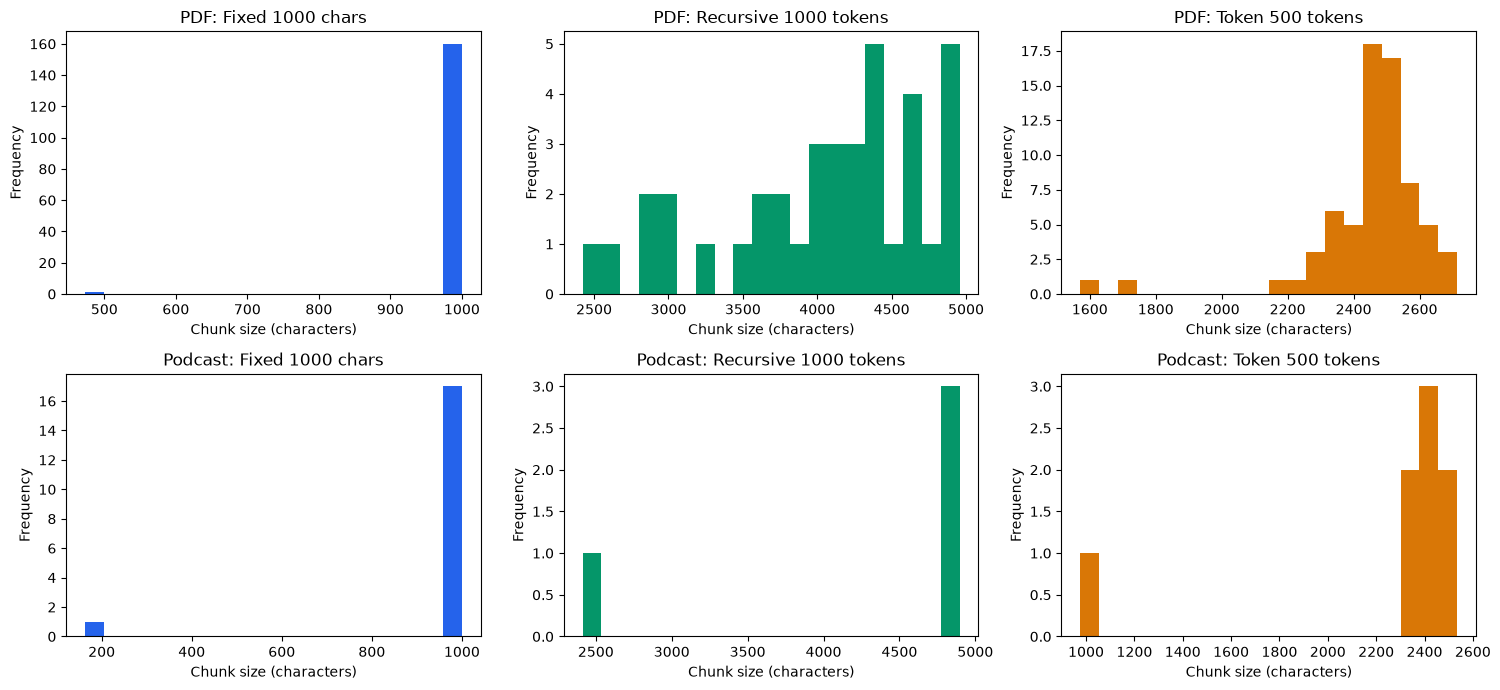

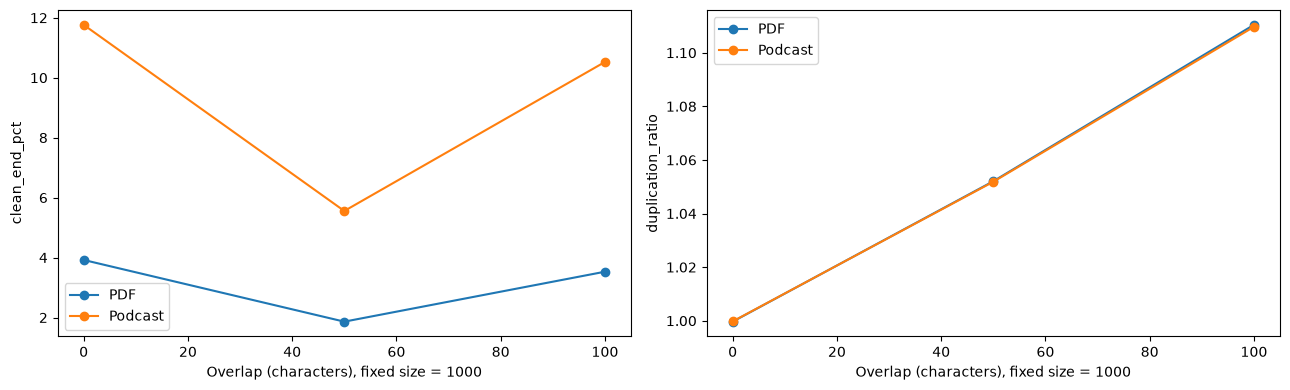

,run,chunk_index,ending,next_start
0,PDF|Fixed|1000|50|default,0,une 2018.\n\nContact Nathalie Smuha - AI HLEG...,une 2018.\n\nContact Nathalie Smuha - AI HLEG...
1,PDF|Fixed|1000|50|default,1,may not in any circumstances be\nregarded as ...,may not in any circumstances be\nregarded as r...
2,PDF|Fixed|1000|50|default,2,tworthy AI 24\nC. EXAMPLES OF OPPORTUNITIES AN...,tworthy AI 24\nC. EXAMPLES OF OPPORTUNITIES AN...
3,PDF|Recursive|1000|50|paragraph-first,0,NS RAISED BY AI 32\nD. CONCLUSION 35\nGLOSSARY...,2\n\nEXECUTIVE SUMMARY\nThe aim of the Guideli...
4,PDF|Recursive|1000|50|paragraph-first,1,so article 38 dealing with consumer protection...,3\n\n Foster research and innovation to help ...
5,PDF|Recursive|1000|50|paragraph-first,2,ember 2018 by the Commission and Member States...,4\n\nA. INTRODUCTION\nIn its Communication of ...
6,PDF|Token|500|50|default,0,"y Decision 2011/8 33/EU (OJ L 330, 14. 12.2011...",-market/en/high-level-expert-group-artificial-...
7,PDF|Token|500|50|default,1,", fr om the most abstract in Chapter I to the\...",seek to go\nbeyond a list of ethical principl...
8,PDF|Token|500|50|default,2,document aim to reflect guidance towards achie...,"fairness, (6) environmental and societal\nwel..."
9,Podcast|Fixed|1000|50|default,0,guidelines for trustworthy A.I. This is a heav...,guidelines for trustworthy A.I. This is a heav...


,key,source,strategy,size,overlap,unit,variant,avg_chars,min_chars,max_chars,n_chunks,avg_tokens,max_tokens,clean_end_pct,oversized,duplication_ratio
33,PDF|Paragraph diagnostic|1000|50|default,PDF,Paragraph diagnostic,1000,50,chars,default,1450.06,1,4173,105,295.37,831,47.62,52,1.00
34,PDF|Recursive chars|1000|50|default,PDF,Recursive chars,1000,50,chars,default,730.46,1,999,209,148.58,306,33.49,0,1.00
68,Podcast|Paragraph diagnostic|1000|50|default,Podcast,Paragraph diagnostic,1000,50,chars,default,16313.00,16313,16313,1,3380.00,3380,100.00,1,1.00
69,Podcast|Recursive chars|1000|50|default,Podcast,Recursive chars,1000,50,chars,default,949.11,170,999,18,197.22,235,11.11,0,1.05


In [4]:
selected=stats[(stats.overlap==50)&((stats.strategy=='Fixed')&(stats['size']==1000)|(stats.strategy=='Recursive')&(stats['size']==1000)&(stats.variant=='paragraph-first')|(stats.strategy=='Token')&(stats['size']==500))]
fig,axes=plt.subplots(2,3,figsize=(15,7))
for row,source in enumerate(texts):
    for col,(_,r) in enumerate(selected[selected.source==source].iterrows()):
        axes[row,col].hist([len(c) for c in runs[r.key]],bins=20,color=['#2563eb','#059669','#d97706'][col])
        axes[row,col].set(title=f'{source}: {r.strategy} {r["size"]} {r.unit}',xlabel='Chunk size (characters)',ylabel='Frequency')
fig.tight_layout(); fig.savefig(RESULTS/'size_distributions.png',dpi=160); plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4))
for ax,metric in zip(axes,['clean_end_pct','duplication_ratio']):
    for source in texts:
        subset=stats[(stats.source==source)&(stats.strategy=='Fixed')&(stats['size']==1000)]
        ax.plot(subset.overlap,subset[metric],marker='o',label=source)
    ax.set(xlabel='Overlap (characters), fixed size = 1000',ylabel=metric); ax.legend()
fig.tight_layout();fig.savefig(RESULTS/'overlap_and_boundaries.png',dpi=160);plt.show()
boundaries=[]
for _,r in selected.iterrows():
    chunks=runs[r.key]
    for i in range(min(3,len(chunks)-1)):
        boundaries.append({'run':r.key,'chunk_index':i,'ending':chunks[i][-50:],'next_start':chunks[i+1][:50]})
(RESULTS/'boundary_examples.json').write_text(json.dumps(boundaries,indent=2),encoding='utf-8')
display(pd.DataFrame(boundaries))
display(stats[stats.strategy.isin(['Paragraph diagnostic','Recursive chars'])].round(2))

## Retrieval trace and overlap experiment

In [5]:
query='What are the three components of trustworthy AI?'
def retrieve(chunks,question,k=3):
    vectorizer=TfidfVectorizer(stop_words='english')
    matrix=vectorizer.fit_transform(chunks)
    scores=cosine_similarity(vectorizer.transform([question]),matrix).ravel()
    return [(int(i),float(scores[i])) for i in np.argsort(-scores,kind='stable')[:k]]
def locate(source,chunk):
    start=texts[source].find(chunk)
    if start<0: return {'verified':False}
    end=start+len(chunk)
    if source=='PDF': return {'verified':True,'start':start,'end':end,'pages':[p['page'] for p in pages if p['start']<end and p['end']>start]}
    matched=[s for s in segments if s['char_start']<end and s['char_end']>start]
    return {'verified':True,'start':start,'end':end,'seconds':[matched[0]['start'],matched[-1]['end']]}
traces=[]; probe=[]
for _,r in stats[stats.strategy.isin(['Fixed','Recursive','Token'])].iterrows():
    hits=retrieve(runs[r.key],query)
    context=' '.join(runs[r.key][i] for i,_ in hits).lower()
    probe.append({'key':r.key,'source':r.source,'phrase_coverage_at_3':sum(w in context for w in ['lawful','ethical','robust'])/3,'retrieved_chars':sum(len(runs[r.key][i]) for i,_ in hits)})
pd.DataFrame(probe).to_csv(RESULTS/'retrieval_probe.csv',index=False)
for source in texts:
    key=f'{source}|Recursive|1000|50|paragraph-first'
    for rank,(i,score) in enumerate(retrieve(runs[key],query),1):
        chunk=runs[key][i]
        traces.append({'source':source,'run':key,'rank':rank,'chunk_id':f'{source.lower()}-recursive-{i:04d}','score':score,'location':locate(source,chunk),'text':chunk})
assert all(t['location']['verified'] for t in traces)
(RESULTS/'retrieval_trace.json').write_text(json.dumps({'query':query,'retriever':'TF-IDF cosine, top 3 per source','hits':traces},indent=2),encoding='utf-8')
# Extractive output preserves wording and makes grounding mechanically checkable.
candidates=[t for t in traces if t['source']=='PDF' and all(w in t['text'].lower() for w in ['lawful','ethical','robust'])]
assert candidates, 'No retrieved PDF evidence supports all three components.'
evidence=candidates[0]
answer=evidence['text']
(RESULTS/'final_output.txt').write_text(answer,encoding='utf-8')
display(Markdown('**Query:** '+query))
for t in traces: print(t['chunk_id'],t['location'],'score=',round(t['score'],4),t['text'][:350])
print('FINAL OUTPUT (verbatim PDF excerpt):\n'+answer)
print('Limitation: lexical retrieval can miss paraphrases; transcription can distort terms. No claim of legal compliance follows from this retrieval.')

**Query:** What are the three components of trustworthy AI?

pdf-recursive-0004 {'verified': True, 'start': 15518, 'end': 19905, 'pages': [7, 8]} score= 0.323 5

benefits that they can bring. To help Europe realise those benefits, our vision is to ensure and scale Trustworthy AI.
Trust in the development, deployment and use of AI systems concern s not only the technology’s inherent
properties, but also the qualities of the socio -technical systems involving AI applications.9 Analogous to questions of
(lo
pdf-recursive-0001 {'verified': True, 'start': 2961, 'end': 7107, 'pages': [4, 5]} score= 0.2995 2

EXECUTIVE SUMMARY
The aim of the Guidelines is to promote Trustworthy AI. Trustworthy AI has three components, which should be
met throughout the system's entire life cycle : (1) it should be lawful, complying with  all applicable laws  and
regulations (2) it should be ethical, ensuring adherence to ethical principles and values and (3) it shoul
pdf-recursive-0006 {'verified': True, 'start': 24297, 'end': 27325, 'pages': [9, 10, 11]} score= 0.2593

## 8. Recommendations and limitations

In [6]:
lines=['## Chunking Strategy Recommendations','']
for source in texts:
    fixed=stats[(stats.source==source)&(stats.strategy=='Fixed')&(stats['size']==1000)&(stats.overlap==50)].iloc[0]
    rec=stats[(stats.source==source)&(stats.strategy=='Recursive')&(stats['size']==1000)&(stats.overlap==50)&(stats.variant=='paragraph-first')].iloc[0]
    diag=stats[(stats.source==source)&(stats.strategy=='Paragraph diagnostic')].iloc[0]
    lines += [f'### For {source}',
      f'Fixed 1000 characters / overlap 50 produced {fixed.n_chunks} chunks and {fixed.clean_end_pct:.1f}% clean endings. Recursive 1000 tokens / overlap 50 produced {rec.n_chunks} chunks and {rec.clean_end_pct:.1f}% clean endings. Different units and resulting context lengths confound a direct quality ranking.',
      f'The default paragraph splitter produced {diag.n_chunks} chunks with maximum {diag.max_chars} characters, including {diag.oversized} chunks above the 1000-character target. The source contains {texts[source].count(chr(10)+chr(10))} paragraph separators.',
      'Recommended starting configuration: recursive splitting, 1000 tokens and 50-token target overlap, paragraph-first separators. '+('Preserve PDF page metadata and inspect section boundaries; line-based extraction does not guarantee heading preservation.' if source=='PDF' else 'Preserve timestamp spans and inspect conversational transitions; the transcript has no reliable speaker labels.'),
      'Use token windows when strict model budgets matter; use fixed character windows as a cheap baseline. Increase overlap only if retrieval gains justify repeated context and indexing cost.','']
lines += ['### Trade-offs Summary','| Strategy | Pros | Cons | Best for |','|---|---|---|---|',
'| Fixed-size | Simple character budget | Cuts words and sentences | Baselines |',
'| Recursive | Prioritizes structural separators | No guaranteed sentence or heading preservation | Structured text |',
'| Token-based | Explicit token windows | Can split sentences and Unicode sequences | Context budgets |',
'| Semantic (not run) | Potential topic-based boundaries | Model dependency and extra computation; unmeasured here | Optional future comparison |',
'', '### Interpretation',
'Clean-ending percentage only checks terminal punctuation. PDF headings and footnotes can lower it without indicating a bad chunk. Sentence-first separators may leave punctuation at the next chunk start. Inspect boundary_examples.json alongside the plots.',
'The retrieval probe reports phrase coverage at top 3 and retrieved characters. It has one query, no independent relevance labels, unequal context budgets, and lexical matching; it cannot establish a universal winner.',
'The podcast is explanatory secondary material. ASR timestamps are approximate, ten-minute piece boundaries can lose context, and audio should be checked before relying on a disputed quotation.']
recommendations='\n'.join(lines)
(RESULTS/'recommendations.md').write_text(recommendations,encoding='utf-8')
display(Markdown(recommendations))
proof=['# Lab Proof','## Scope and workflow',
'Executed chunking_strategies.ipynb loads the assigned PDF and podcast, caches Whisper transcription, evaluates fixed/recursive/token configurations, writes metrics and figures, and retrieves inspectable evidence. Semantic chunking is explicitly optional and not run.',
'## Reproduce','Install requirements.txt in a virtual environment, put the two instructor files in the parent folder (or edit SOURCE in the notebook), configure local .env, and run the notebook from top to bottom. Cached transcription avoids repeat API calls. Never commit .env or the original audio.',
'## Query',query,'## Retrieved evidence','See results/retrieval_trace.json for complete ranked chunks, cosine scores, character spans, PDF physical page numbers, and approximate podcast timestamps. Source hashes are in data/source_manifest.json.',
f"Selected evidence: {evidence['chunk_id']}, physical PDF pages {evidence['location']['pages']}; the full output below is an exact substring of both the retrieved chunk and the extracted PDF.",
'## Final output (extractive, verbatim)','```text\n'+answer+'\n```',
'## Verification',f'Executed {len(stats)} configurations on both sources. Assertions check nonempty chunks, size ceilings except the intentional paragraph diagnostic, source-span provenance, and retrieved support for lawful/ethical/robust. All figures are saved under results/.',
'## Failure and limitation','The default paragraph separator can produce oversized chunks when there are no paragraph breaks. See the measured paragraph diagnostic in results/chunk_statistics.csv. Terminal punctuation is not semantic coherence; top-3 lexical phrase coverage on one query is not a retrieval benchmark. No LLM answer is generated: the final output is intentionally extractive.',
'## Deliverables','chunking_strategies.ipynb; requirements.txt; data/transcript.txt and timestamp JSON; extracted PDF and page JSON; source manifest; results/chunk_statistics.csv; retrieval_probe.csv; boundary_examples.json; figures; retrieval_trace.json; final_output.txt; recommendations.md; environment.json.',
'## Assistance disclosure','AI assisted implementation, execution, and analysis drafting at the student request. The assignment Prompt Discipline restricts AI use to review/debug/critique. This submission must not be represented as unaided student work; the student should review and revise the conclusions and clarify acceptability with the instructor.',
'## Recommendations',recommendations]
(ROOT/'lab_proof.md').write_text('\n\n'.join(proof),encoding='utf-8')
(ROOT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in versions.items())+'\n',encoding='utf-8')
print('Saved proof, recommendations, pinned environment, and evidence artifacts.')

## Chunking Strategy Recommendations

### For PDF
Fixed 1000 characters / overlap 50 produced 161 chunks and 1.9% clean endings. Recursive 1000 tokens / overlap 50 produced 38 chunks and 23.7% clean endings. Different units and resulting context lengths confound a direct quality ranking.
The default paragraph splitter produced 105 chunks with maximum 4173 characters, including 52 chunks above the 1000-character target. The source contains 169 paragraph separators.
Recommended starting configuration: recursive splitting, 1000 tokens and 50-token target overlap, paragraph-first separators. Preserve PDF page metadata and inspect section boundaries; line-based extraction does not guarantee heading preservation.
Use token windows when strict model budgets matter; use fixed character windows as a cheap baseline. Increase overlap only if retrieval gains justify repeated context and indexing cost.

### For Podcast
Fixed 1000 characters / overlap 50 produced 18 chunks and 5.6% clean endings. Recursive 1000 tokens / overlap 50 produced 4 chunks and 25.0% clean endings. Different units and resulting context lengths confound a direct quality ranking.
The default paragraph splitter produced 1 chunks with maximum 16313 characters, including 1 chunks above the 1000-character target. The source contains 0 paragraph separators.
Recommended starting configuration: recursive splitting, 1000 tokens and 50-token target overlap, paragraph-first separators. Preserve timestamp spans and inspect conversational transitions; the transcript has no reliable speaker labels.
Use token windows when strict model budgets matter; use fixed character windows as a cheap baseline. Increase overlap only if retrieval gains justify repeated context and indexing cost.

### Trade-offs Summary
| Strategy | Pros | Cons | Best for |
|---|---|---|---|
| Fixed-size | Simple character budget | Cuts words and sentences | Baselines |
| Recursive | Prioritizes structural separators | No guaranteed sentence or heading preservation | Structured text |
| Token-based | Explicit token windows | Can split sentences and Unicode sequences | Context budgets |
| Semantic (not run) | Potential topic-based boundaries | Model dependency and extra computation; unmeasured here | Optional future comparison |

### Interpretation
Clean-ending percentage only checks terminal punctuation. PDF headings and footnotes can lower it without indicating a bad chunk. Sentence-first separators may leave punctuation at the next chunk start. Inspect boundary_examples.json alongside the plots.
The retrieval probe reports phrase coverage at top 3 and retrieved characters. It has one query, no independent relevance labels, unequal context budgets, and lexical matching; it cannot establish a universal winner.
The podcast is explanatory secondary material. ASR timestamps are approximate, ten-minute piece boundaries can lose context, and audio should be checked before relying on a disputed quotation.

Saved proof, recommendations, pinned environment, and evidence artifacts.


## Answers to the analysis questions (measured results)



### PDF

Fixed windows break sentences: 98.1% of 1000-character / 50-overlap chunks do not end with `.?!`. They may also cut words. Recursive splitting at the same character budget has 33.5% clean endings, compared with 1.9% for fixed windows.

Recursive 1000-token paragraph-first chunks have 23.7% clean endings; sentence-first chunks have 2.9%. Separator order changes segmentation, but neither configuration explicitly recognizes PDF headers or podcast speaker turns.

Token-500 / 50-overlap produces 69 chunks averaging 2452.7 characters, with maximum 500 tokens. A 500-token budget is not equivalent to 500 characters.



### Podcast

Fixed windows break sentences: 94.4% of 1000-character / 50-overlap chunks do not end with `.?!`. They may also cut words. Recursive splitting at the same character budget has 11.1% clean endings, compared with 5.6% for fixed windows.

Recursive 1000-token paragraph-first chunks have 25.0% clean endings; sentence-first chunks have 25.0%. Separator order changes segmentation, but neither configuration explicitly recognizes PDF headers or podcast speaker turns.

Token-500 / 50-overlap produces 8 chunks averaging 2243.5 characters, with maximum 500 tokens. A 500-token budget is not equivalent to 500 characters.



### Which source handles fixed windows better?

At the matched 1000-character / 50-overlap setting, PDF has 1.9% clean endings and the podcast has 5.6%. Podcast performs better on this punctuation heuristic only; the difference does not prove better semantic coherence or retrieval.

### Which strategy preserves context best?

Recursive splitting is a reasonable starting choice because it tries structural separators before cutting words, while token windows give a direct token budget. The matched character comparison above and saved boundary examples support inspection, but punctuation alone cannot prove a semantic winner. For PDF retain pages and inspect headings; for the podcast retain timestamps and inspect transitions.



### Parameter sensitivity
The following table summarizes all measured fixed-window sizes and overlaps; full recursive and token grids are in results/chunk_statistics.csv.

| Source | Size (characters) | Overlap (characters) | Chunks | Clean endings (%) |
|---|---:|---:|---:|---:|
| PDF | 500 | 0 | 305 | 2.6 |
| PDF | 500 | 50 | 339 | 1.8 |
| PDF | 500 | 100 | 381 | 1.3 |
| PDF | 1000 | 0 | 153 | 3.9 |
| PDF | 1000 | 50 | 161 | 1.9 |
| PDF | 1000 | 100 | 170 | 3.5 |
| PDF | 2000 | 0 | 77 | 5.2 |
| PDF | 2000 | 50 | 79 | 2.5 |
| PDF | 2000 | 100 | 81 | 1.2 |
| Podcast | 500 | 0 | 33 | 9.1 |
| Podcast | 500 | 50 | 37 | 13.5 |
| Podcast | 500 | 100 | 41 | 7.3 |
| Podcast | 1000 | 0 | 17 | 11.8 |
| Podcast | 1000 | 50 | 18 | 5.6 |
| Podcast | 1000 | 100 | 19 | 10.5 |
| Podcast | 2000 | 0 | 9 | 11.1 |
| Podcast | 2000 | 50 | 9 | 11.1 |
| Podcast | 2000 | 100 | 9 | 22.2 |